In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# =========================
# LOAD DATA
# =========================

#sns.set_theme(style="white")

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 14,
    "axes.labelsize": 12,
    "axes.titlesize": 14,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "lines.linewidth": 1,
    "axes.linewidth": 0.8,
    "figure.dpi": 300
})

df = pd.read_csv("experiment_metrics.csv")

# Clean up attack names
attack_map = {
    "Mirai_malicious.pcap":      "Mirai Botnet",
    "SSDP_Flood_malicious.pcap": "SSDP Flood",
    "BruteForce_malicious.pcap": "Brute Force",
    "DDoS_malicious.pcap":       "DDoS",
    "PortScan_malicious.pcap":   "Port Scan",
}
df["Attack"] = df["file"].map(attack_map)

attack_order   = ["Brute Force", "DDoS", "Port Scan", "Mirai Botnet", "SSDP Flood"]
df["Attack"] = pd.Categorical(df["Attack"], categories=attack_order, ordered=True)

feature_map = {
    "Both": "Both",
    "iat":  "IAT",
    "size": "Size",
}
df["Feature"] = df["feature"].map(feature_map)


In [2]:
# =========================
# AGGREGATE: mean over batch sizes, per attack + feature
# =========================

agg = df.groupby(["Attack", "Feature"]).agg(
    throughput_packets=("throughput_packets", "mean"),
    latency_per_packet=("latency_per_packet", "mean"),
    cpu_avg=("cpu_avg", "mean"),
    ram_avg=("ram_avg", "mean"),
    gpu_utilization=("gpu_utilization", "mean"),
    gpu_memory_peak=("gpu_memory_peak", "mean"),
    inference_time=("inference_time", "mean"),
    features_extraction_time=("features_extraction_time", "mean"),
    rebuild_time=("rebuild_time", "mean"),
    total_time=("total_time", "mean"),
).reset_index()

# =========================
# PRINT LATEX TABLE
# =========================

attack_order   = ["Brute Force", "DDoS", "Port Scan", "Mirai Botnet", "SSDP Flood"]
feature_order  = ["IAT", "Size", "Both"]

print("% ===== LaTeX Table =====")
print(r"\begin{table}[htbp]")
print(r"    \centering")
print(r"    \caption{TANTGen End-to-End Computational Cost}")
print(r"    \label{tab:cost}")
print(r"    \begin{tabular}{@{}llccccc@{}}")
print(r"        \toprule")
print(r"        \textbf{Attack} & \textbf{Feature} & \textbf{Throughput} & \textbf{Latency} & \textbf{CPU} & \textbf{RAM} & \textbf{GPU} \\")
print(r"        & & \textit{(pkt/s)} & \textit{(ms/pkt)} & \textit{(\%)} & \textit{(\%)} & \textit{(\%)} \\")
print(r"        \midrule")

for i, attack in enumerate(attack_order):
    first = True
    for feature in feature_order:
        row = agg[(agg["Attack"] == attack) & (agg["Feature"] == feature)]
        if row.empty:
            continue
        r = row.iloc[0]
        attack_label = f"\\multirow[t]{{3}}{{*}}{{{attack}}}" if first else ""
        print(f"        {attack_label} & {feature} & "
              f"{r['throughput_packets']:.1f} & "
              f"{r['latency_per_packet']:.2f} & "
              f"{r['cpu_avg']:.1f} & "
              f"{r['ram_avg']:.2f} & "
              f"{r['gpu_utilization']:.1f} \\\\")
        first = False
    if i < len(attack_order) - 1:
        print(r"        \cline{1-7}")
        print(r"        \addlinespace[4pt]")

print(r"        \bottomrule")
print(r"    \end{tabular}")
print(r"\end{table}")

% ===== LaTeX Table =====
\begin{table}[htbp]
    \centering
    \caption{TANTGen End-to-End Computational Cost}
    \label{tab:cost}
    \begin{tabular}{@{}llccccc@{}}
        \toprule
        \textbf{Attack} & \textbf{Feature} & \textbf{Throughput} & \textbf{Latency} & \textbf{CPU} & \textbf{RAM} & \textbf{GPU} \\
        & & \textit{(pkt/s)} & \textit{(ms/pkt)} & \textit{(\%)} & \textit{(\%)} & \textit{(\%)} \\
        \midrule
        \multirow[t]{3}{*}{Brute Force} & IAT & 1119.0 & 0.89 & 288.4 & 0.57 & 5.2 \\
         & Size & 879.9 & 1.14 & 304.5 & 0.59 & 5.2 \\
         & Both & 877.6 & 1.14 & 308.6 & 0.59 & 4.8 \\
        \cline{1-7}
        \addlinespace[4pt]
        \multirow[t]{3}{*}{DDoS} & IAT & 1663.2 & 0.60 & 188.0 & 0.57 & 7.4 \\
         & Size & 749.6 & 1.33 & 196.3 & 0.60 & 7.2 \\
         & Both & 749.0 & 1.34 & 186.6 & 0.60 & 7.6 \\
        \cline{1-7}
        \addlinespace[4pt]
        \multirow[t]{3}{*}{Port Scan} & IAT & 1912.2 & 0.52 & 133.5 & 0.57 & 10.7 \\
 

/tmp/user/1403/ipykernel_2809863/3252445092.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agg = df.groupby(["Attack", "Feature"]).agg(


In [15]:
inference_time = df["inference_time"].values
print(inference_time)

total_packets = df["throughput_packets"].values * df["total_time"].values
print(total_packets)

inference_throughput = total_packets / inference_time
print(inference_throughput)

[6.60078859e+00 4.34626818e-01 3.88466835e-01 3.74737263e-01
 6.06724739e+00 3.93512726e-01 3.50543022e-01 3.34978342e-01
 6.61556220e+00 4.41022635e-01 3.91399860e-01 3.76404285e-01
 9.56870461e+00 6.16739273e-01 5.56596756e-01 5.35009146e-01
 5.75052738e-01 8.95238829e+00 5.15718222e-01 4.98084545e-01
 1.01247072e+01 6.21145487e-01 5.56697845e-01 5.38153648e-01
 1.35559320e-01 5.39696217e-02 4.81164455e-02 4.75859642e-02
 7.69948959e-03 8.62815380e-02 1.17239952e-02 7.25674629e-03
 1.34004116e-01 5.27906418e-02 4.69574928e-02 4.69489098e-02
 3.86409283e-01 6.66091442e-02 6.09843731e-02 5.97162247e-02
 3.12543631e-01 2.41947174e-02 2.16176510e-02 2.08680630e-02
 3.81072044e-01 6.66387081e-02 6.25333786e-02 6.21168613e-02
 1.12808681e+00 1.10155344e-01 1.00726843e-01 9.75279808e-02
 1.00572824e+00 7.25653172e-02 6.16173744e-02 5.85675240e-02
 1.14994979e+00 1.13759756e-01 1.03343487e-01 9.94672775e-02]
[192768. 192768. 192768. 192768. 192768. 192768. 192768. 192768. 192768.
 192768. 19

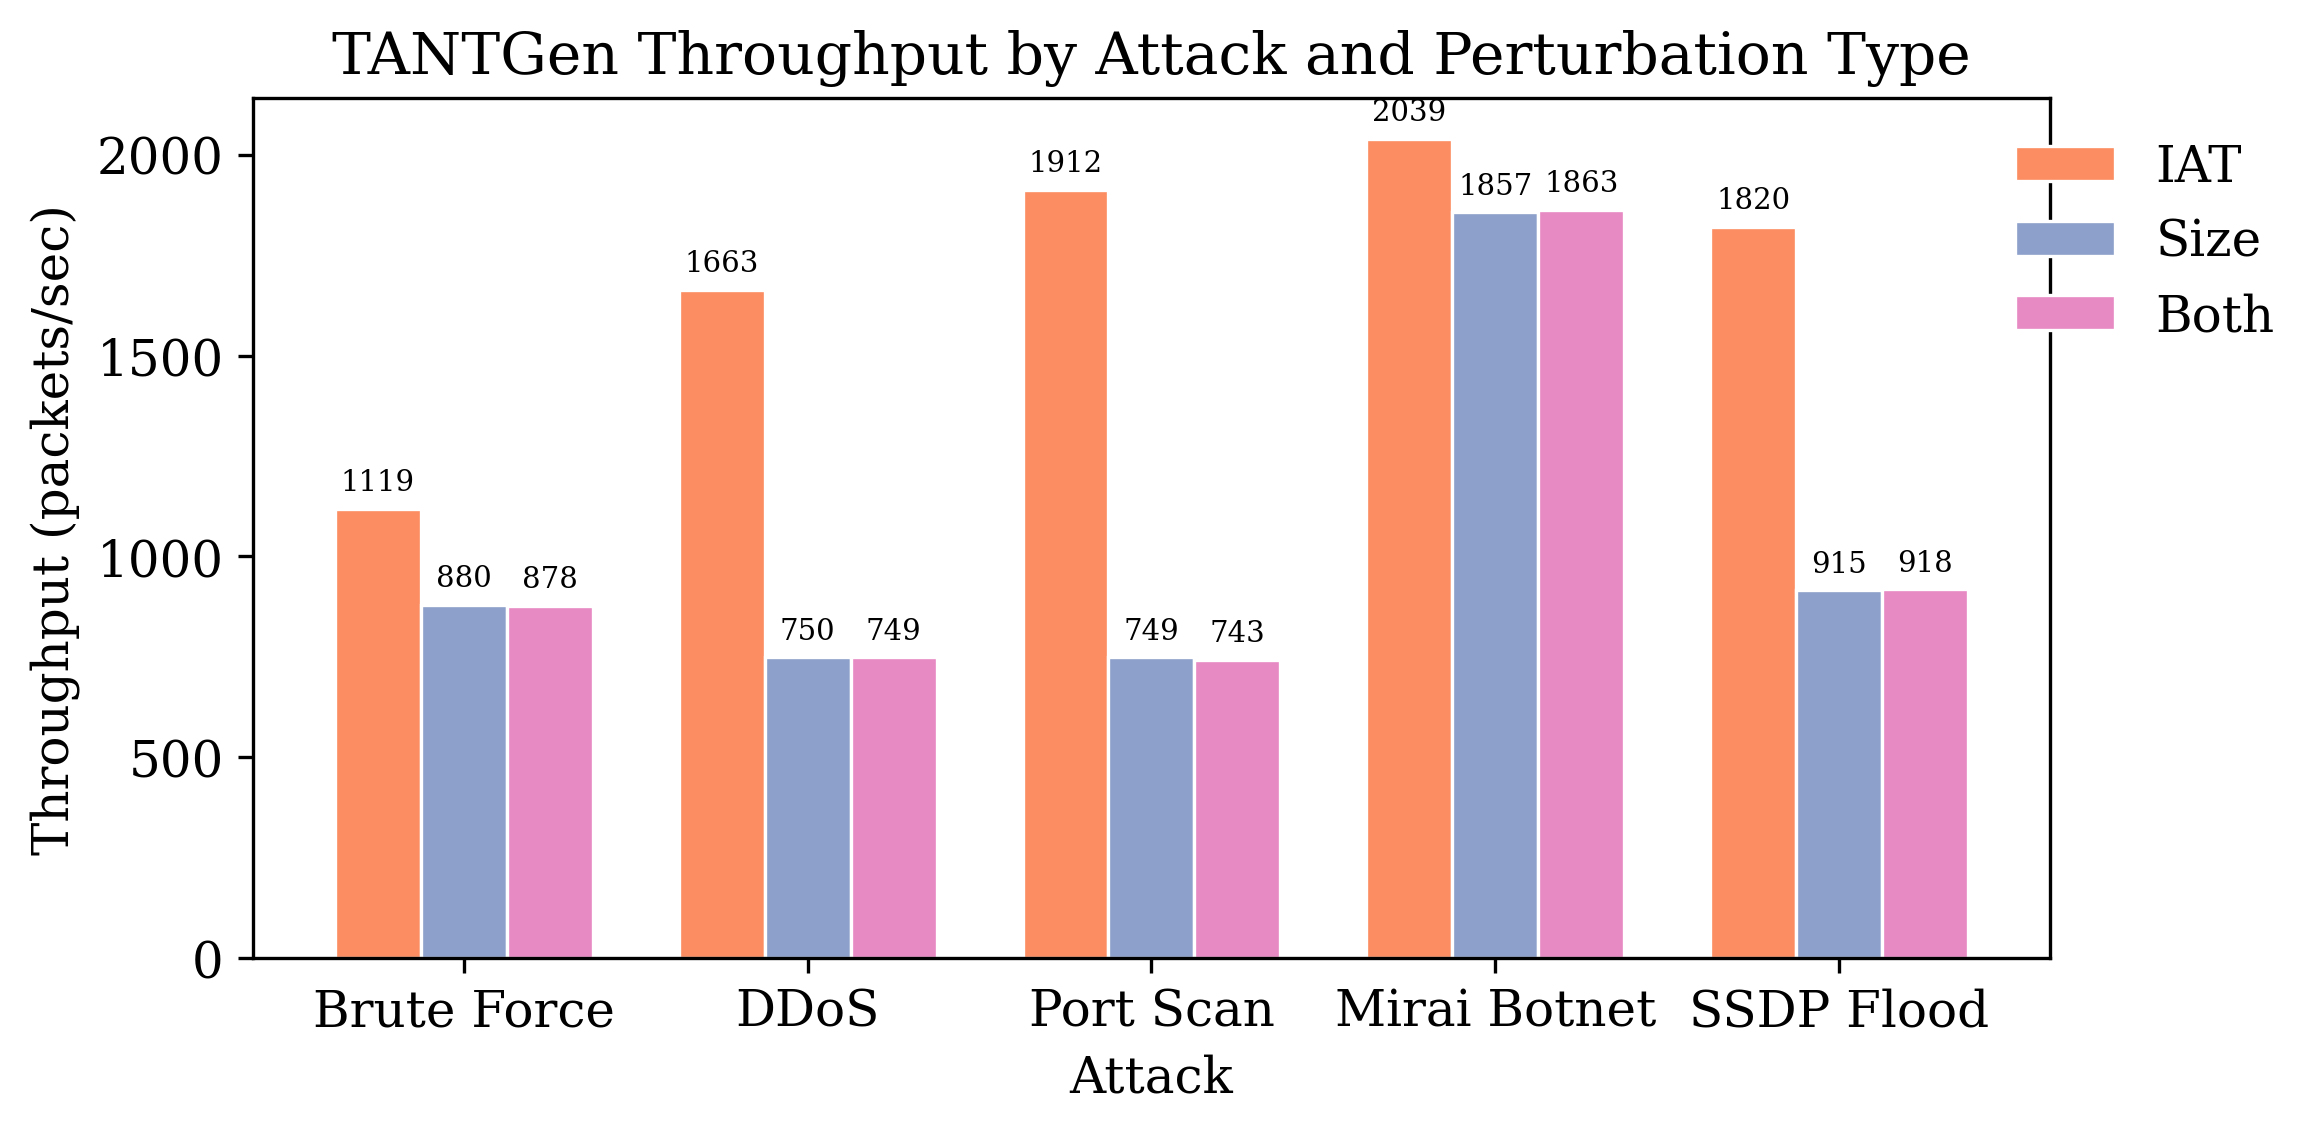


Saved cost_throughput


In [3]:
# =========================
# PLOT 1: Throughput by attack and feature
# =========================
import seaborn as sns

palette = sns.color_palette("Set2")

colors = {
    "IAT": palette[1],
    "Size": palette[2],
    "Both": palette[3],
}

fig, ax = plt.subplots(figsize=(8, 4))

x = np.arange(len(attack_order))
width = 0.25
offsets = [-width, 0, width]

for idx, feature in enumerate(feature_order):
    vals = []
    for attack in attack_order:
        row = agg[(agg["Attack"] == attack) & (agg["Feature"] == feature)]
        vals.append(row["throughput_packets"].values[0] if not row.empty else 0)
    bars = ax.bar(x + offsets[idx], vals, width,
                  label=feature, color=colors[feature],
                  edgecolor="white", linewidth=0.8)
    for bar, val in zip(bars, vals):
        if val > 0:
            ax.annotate(f"{val:.0f}",
                        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                        xytext=(0, 3), textcoords="offset points",
                        ha="center", va="bottom", fontsize=7)

ax.set_xticks(x)
ax.set_xticklabels(attack_order)
ax.set_ylabel("Throughput (packets/sec)")
ax.set_xlabel("Attack")
ax.set_title("TANTGen Throughput by Attack and Perturbation Type")
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1.15, 1))
plt.tight_layout()
plt.show()
# plt.savefig("plots/cost_throughput.png", bbox_inches="tight", dpi=300)
# plt.close()
print("\nSaved cost_throughput")

In [4]:
# =========================
# PLOT 1: Throughput by attack and feature
# =========================
import seaborn as sns

palette = sns.color_palette("Set2")

colors = {
    "IAT": palette[1],
    "Size": palette[2],
    "Both": palette[3],
}

plt.figure(figsize=(8, 4))

hue_order = ["IAT", "Size", "Both"]

ax = sns.barplot(
    data=df,
    x="Attack",
    y="throughput_packets",
    hue="Feature",
    hue_order=hue_order,
    palette=colors,
    errorbar=None,
)

ax.set_xlabel("Attack")
ax.set_ylabel("Throughput (packets/sec)")

for container in ax.containers:
    ax.bar_label(container, fmt="%d", fontsize=6, padding=2)

# remover top/right spines
sns.despine()

# legenda compacta
ax.legend(title="", frameon=False, loc="upper left", bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.savefig(f"plots/throughput_by_attack_and_feature.png", bbox_inches="tight", dpi=300)
plt.close()
plt.show()

In [5]:
# =========================
# PLOT 2: Time breakdown (stacked bar) — averaged over features
# =========================
import seaborn as sns

time_agg = df.groupby("Attack").agg(
    features_extraction_time=("features_extraction_time", "mean"),
    inference_time=("inference_time", "mean"),
    rebuild_time=("rebuild_time", "mean"),
).reset_index()
time_agg["Attack"] = pd.Categorical(time_agg["Attack"],
                                     categories=attack_order, ordered=True)
time_agg = time_agg.sort_values("Attack")

fig, ax = plt.subplots(figsize=(10, 4))

bar_colors = sns.color_palette("YlGnBu")[1:] #"YlGnBu")[1:] YlGnBu#("pastel") #["#5B8DB8", "#E8956D", "#6DBE8C"]
labels_time = ["Feature\nExtraction", "Inference", "Packet\nRebuild"]
bottom = np.zeros(len(time_agg))

for col, label, color in zip(
    ["features_extraction_time", "inference_time", "rebuild_time"],
    labels_time, bar_colors
):
    vals = time_agg[col].values
    ax.bar(time_agg["Attack"], vals, bottom=bottom,
           label=label, color=color, edgecolor="white", linewidth=0.8)
    bottom += vals

ax.set_ylabel("Time (seconds)")
ax.set_xlabel("Attack")
ax.set_title("TANTGen Processing Time Breakdown")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.savefig("plots/cost_time_breakdown.png", bbox_inches="tight")
plt.close()
print("Saved cost_time_breakdown")

/tmp/user/1403/ipykernel_2809863/2637862150.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  time_agg = df.groupby("Attack").agg(


Saved cost_time_breakdown


In [8]:
time_agg_pct = time_agg.copy()

total = (
    time_agg["features_extraction_time"] +
    time_agg["inference_time"] +
    time_agg["rebuild_time"]
)

time_agg_pct["features_extraction_time"] /= total
time_agg_pct["inference_time"] /= total
time_agg_pct["rebuild_time"] /= total

fig, ax = plt.subplots(figsize=(10, 4))

bottom = np.zeros(len(time_agg_pct))

for col, label, color in zip(
    ["features_extraction_time", "inference_time", "rebuild_time"],
    labels_time, bar_colors
):
    vals = time_agg_pct[col].values
    ax.bar(time_agg_pct["Attack"], vals, bottom=bottom,
           label=label, color=color, edgecolor="white", linewidth=0.8)
    bottom += vals

ax.set_ylabel("Percentage of Total Time")
ax.set_title("")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))

# remover top/right spines
sns.despine()

plt.tight_layout()
plt.savefig("plots/cost_time_breakdown.png", bbox_inches="tight")
plt.close()
print("Saved cost_time_breakdown")

Saved cost_time_breakdown
